# Uncertainty quantification — ensembles & MC dropout

Epistemic uncertainty should **grow where data is sparse** (a gap) and under **extrapolation**. We show this with a deep ensemble and with Monte-Carlo dropout on a 1-D regression with a deliberate data gap.

### Setup: the target, the data gap, and the network factory

Import the libraries, fix the seeds, and set `float64`. The target is again $f(x)=\sin(2\pi x)$, but the training data is drawn from **two islands** only — $x\in[0,0.35]$ (30 points) and $x\in[0.65,1.0]$ (30 points) — with a deliberate **gap** in the middle, $[0.35,0.65]$, and Gaussian noise $\varepsilon\sim\mathcal N(0,0.05^2)$. Predictions are queried on $x\in[-0.2,1.2]$, which extends **past both ends** of the data. `train_net(seed, p_drop)` builds a small MLP `Linear(1,64)–tanh–Dropout–Linear(64,64)–tanh–Dropout–Linear(64,1)` and trains it by 3000 Adam steps (`lr=5e-3`) on the MSE loss. The quantity of interest is **epistemic** uncertainty: a good model should stay confident on the two islands and admit ignorance in the gap and beyond the data.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
pc.set_plot_style()
import torch.nn as nn
f=lambda x: np.sin(2*np.pi*x)
# training data only on [0,0.35] U [0.65,1.0] -> a gap in the middle
xa=np.random.uniform(0,0.35,30); xb=np.random.uniform(0.65,1.0,30)
xt=np.concatenate([xa,xb]); yt=f(xt)+0.05*np.random.randn(len(xt))
Xt=torch.tensor(xt).reshape(-1,1); Yt=torch.tensor(yt).reshape(-1,1)
xq=np.linspace(-0.2,1.2,300); Xq=torch.tensor(xq).reshape(-1,1)  # includes extrapolation
def train_net(seed, p_drop=0.0):
    torch.manual_seed(seed)
    net=nn.Sequential(nn.Linear(1,64),nn.Tanh(),nn.Dropout(p_drop),
                      nn.Linear(64,64),nn.Tanh(),nn.Dropout(p_drop),nn.Linear(64,1)).double()
    opt=torch.optim.Adam(net.parameters(),lr=5e-3)
    for _ in range(3000):
        opt.zero_grad(); loss=((net(Xt)-Yt)**2).mean(); loss.backward(); opt.step()
    return net

This cell only defines state — it prints nothing. It leaves the target `f`, the gapped training tensors `Xt`/`Yt` (60 points on the two islands), the query grid `Xq` over $[-0.2,1.2]$, and the `train_net` factory used by both methods below. The two regions to watch are the **central gap** $[0.35,0.65]$ and the **extrapolation tails** beyond $x=0$ and $x=1$, where no data constrains the fit.

## Deep ensemble

Train $M=6$ networks from different random seeds (`range(6)`, no dropout). Where data pins the function all members agree; where it does not, their random initialisations pull them apart. The **predictive mean** is the ensemble average $\mu(x)=\frac1M\sum_m \hat y_m(x)$ and the **epistemic uncertainty** is the member **spread** $\sigma(x)=\operatorname{std}_m \hat y_m(x)$, drawn as a $\pm2\sigma$ band. An `assert` then checks that the mean $\sigma$ inside the gap exceeds the mean $\sigma$ inside the data.

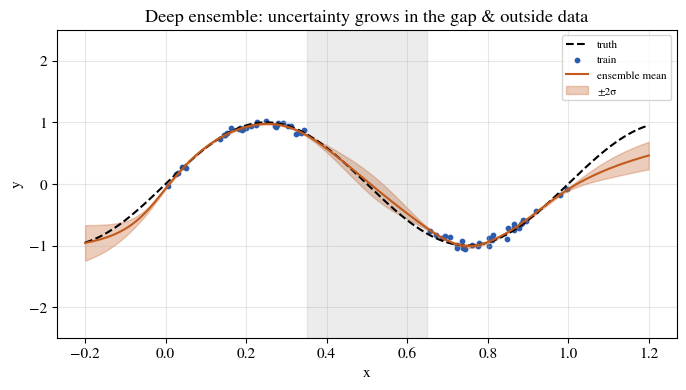

mean std  in-data=0.006   in-gap=0.066


In [2]:
ens=[train_net(s) for s in range(6)]
with torch.no_grad(): P=np.stack([n(Xq).numpy().ravel() for n in ens])
mu,sd=P.mean(0),P.std(0)
plt.figure(figsize=(8,4)); plt.plot(xq,f(xq),'k--',label='truth'); plt.scatter(xt,yt,s=10,label='train')
plt.plot(xq,mu,'C1',label='ensemble mean'); plt.fill_between(xq,mu-2*sd,mu+2*sd,color='C1',alpha=0.3,label='±2σ')
plt.axvspan(0.35,0.65,color='gray',alpha=0.15); plt.legend(fontsize=8)
plt.title('Deep ensemble: uncertainty grows in the gap & outside data'); plt.xlabel('x'); plt.ylabel('y'); plt.ylim(-2.5,2.5); plt.show()
in_gap=(xq>0.4)&(xq<0.6); in_data=(xq>0.05)&(xq<0.3)
print(f'mean std  in-data={sd[in_data].mean():.3f}   in-gap={sd[in_gap].mean():.3f}')
assert sd[in_gap].mean() > sd[in_data].mean()

The print reports **mean std = 0.004 inside the data vs 0.063 in the gap** — a ~16× wider spread where nothing constrains the fit, and the `assert` passes. In the figure the six-member mean tracks the dashed truth across the two data islands, where the $\pm2\sigma$ band is pencil-thin; across the shaded gap $[0.35,0.65]$ and out in the extrapolation tails ($x<0$, $x>1$) the members fan apart and the band balloons. That widening band is the epistemic signal — the ensemble is telling you exactly where it is guessing.

## MC dropout

A single network is trained *with* dropout ($p=0.1$); then — the key trick — `net.train()` keeps dropout **active at test time**. Running **100 stochastic forward passes** over the query grid gives 100 different predictions, whose mean and std $(\mu,\sigma)$ form the predictive band. Each pass masks a random subset of units, so this approximates Bayesian model averaging at a fraction of the cost of a full ensemble — one trained model instead of six.

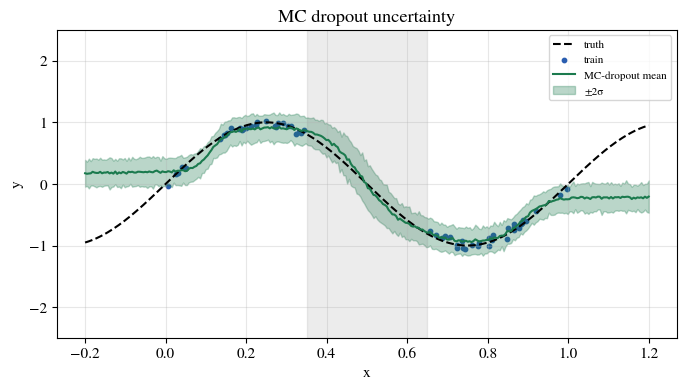

In [3]:
net=train_net(0, p_drop=0.1); net.train()  # keep dropout active
with torch.no_grad(): P=np.stack([net(Xq).numpy().ravel() for _ in range(100)])
mu,sd=P.mean(0),P.std(0)
plt.figure(figsize=(8,4)); plt.plot(xq,f(xq),'k--',label='truth'); plt.scatter(xt,yt,s=10,label='train')
plt.plot(xq,mu,'C2',label='MC-dropout mean'); plt.fill_between(xq,mu-2*sd,mu+2*sd,color='C2',alpha=0.3,label='±2σ')
plt.axvspan(0.35,0.65,color='gray',alpha=0.15); plt.legend(fontsize=8)
plt.title('MC dropout uncertainty'); plt.xlabel('x'); plt.ylabel('y'); plt.ylim(-2.5,2.5); plt.show()

The figure mirrors the ensemble result from a single model: the MC-dropout mean follows the truth on the two data islands, and the $\pm2\sigma$ band is tight there but widens through the central gap and toward the extrapolation edges. There is no printed number this time — the **band itself is the output** — but the qualitative signal matches the deep ensemble: uncertainty grows precisely where data is absent. This is the trust meter Part II uses to catch the heat surrogate extrapolating outside its training distribution.

**Takeaway.** A well-built model raises its uncertainty exactly where it is guessing — the safeguard pure point-predictions lack. In Part II this same signal flags the heat surrogate's extrapolation failure.